In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

In [ ]:
msg = pd.read_csv("message.csv", header=None)
msg.columns = ["time", "type", "order_id", "size", "price", "direction"]
print(msg.size)
msg = msg.iloc[:20000]
msg["time"] -= msg["time"].iloc[0]

4012590


In [ ]:
streams = [[] for _ in range(6)]

for _, row in msg.iterrows():
    t, typ, d = row["time"], row["type"], row["direction"]

    if typ == 4:
        streams[0 if d==1 else 1].append(t)
    elif typ == 1:
        streams[2 if d==1 else 3].append(t)
    elif typ in [2,3]:
        streams[4 if d==1 else 5].append(t)

timestamps = [np.array(s) for s in streams]
d = len(timestamps)


In [ ]:
events = []
for i in range(d):
    for t in timestamps[i]:
        events.append((t, i))

events.sort()
times = np.array([e[0] for e in events])
types = np.array([e[1] for e in events])
T = times[-1]

In [ ]:
def fast_loglik(params):
    mu = params[:d]
    alpha = params[d:].reshape(d,d)

    if np.any(mu < 0) or np.any(alpha < 0):
        return 1e10

    R = np.zeros((d,d))  # recursion memory
    loglik = 0

    prev_t = 0

    for k in range(len(times)):
        t = times[k]
        i = types[k]

        dt = t - prev_t
        R *= np.exp(-1.5 * dt)

        lam = mu[i] + np.sum(alpha[:,i] * R[:,i])

        if lam <= 0:
            return 1e10

        loglik += np.log(lam)

        # update recursion
        R[i,:] += 1

        prev_t = t

    # integral term
    loglik -= np.sum(mu) * T
    for j in range(d):
      for i in range(d):
          for t_j in timestamps[j]:
              loglik -= alpha[j,i] * (1 - np.exp(-1.5 * (T - t_j))) / 1.5

    return -loglik

In [ ]:
params0 = np.ones(d + d*d) * 0.1

res = minimize(fast_loglik, params0, method='L-BFGS-B',
               options={'maxiter': 30})

params = res.x
mu = params[:d]
alpha = params[d:].reshape(d,d)

# stability
eigvals = np.linalg.eigvals(alpha)
rho = max(abs(eigvals))
alpha = alpha / (rho + 1e-6) * 0.7
alpha *= 0.3
print("mu:", mu)
print("alpha:\n", alpha)

mu: [0.11889398 0.10992203 0.126635   0.13510034 0.11470511 0.11854349]
alpha:
 [[2.96784504e-02 1.30216635e-02 1.79298694e-02 3.35931551e-02
  1.82049036e-02 2.69566483e-02]
 [1.28441414e-02 3.82710848e-02 4.08682691e-02 2.02986566e-02
  3.10406584e-02 2.11862488e-02]
 [6.43987406e-03 5.32129818e-03 9.36778949e-02 3.00247879e-02
  8.65360859e-02 2.30269770e-02]
 [1.01182601e-02 9.15887498e-03 3.09483997e-02 8.50598600e-02
  2.47180702e-02 7.34306631e-02]
 [7.05561060e-03 3.16375546e-05 6.50471567e-02 2.91263194e-02
  6.41053787e-02 2.29444662e-02]
 [4.54475457e-03 1.03615570e-02 3.66678627e-02 5.26119492e-02
  2.72412902e-02 5.18096243e-02]]


In [ ]:
alpha/=2

In [ ]:
def simulate(mu, alpha, beta, T_max):
    d = len(mu)
    events = [[] for _ in range(d)]
    t = 0

    while t < T_max:
        intensities = np.array(mu)

        for i in range(d):
            for j in range(d):
                for tj in events[j][-20:]:
                    intensities[i] += alpha[j,i]*np.exp(-beta*(t-tj))

        lam = np.sum(intensities)
        if lam <= 0:
            break

        t += -np.log(np.random.rand()) / lam

        if t >= T_max:
            break

        dim = np.random.choice(d, p=intensities/lam)
        events[dim].append(t)

    return events

sim_events = simulate(mu*2, alpha, 1.5, 100)

In [ ]:
ob = pd.read_csv("orderbook.csv", header=None).iloc[:len(msg)]

# raw prices (LOBSTER usually scaled by 10000)
best_ask_real = ob[0].values
best_bid_real = ob[2].values

# OPTIONAL: convert to actual price
scale = 10000
best_ask_real = best_ask_real / scale
best_bid_real = best_bid_real / scale

real_mid = (best_ask_real + best_bid_real) / 2
real_time = msg["time"].values

# =========================================
# REAL QUEUE DISTRIBUTION
# =========================================
real_bid_q = ob[3].values / scale   # BidSize1
real_ask_q = ob[1].values / scale   # AskSize1

# remove zeros (important)
real_bid_q = real_bid_q[real_bid_q > 0]
real_ask_q = real_ask_q[real_ask_q > 0]

In [ ]:
sizes = msg["size"].values
# 🔥 initialize from REAL market
best_bid = best_bid_real[0]
best_ask = best_ask_real[0]

tick = best_ask - best_bid

bid_q = np.random.choice(real_bid_q)
ask_q = np.random.choice(real_ask_q)

sim_mid, sim_time = [], []

events_flat = []
for i, ts in enumerate(sim_events):
    for t in ts:
        events_flat.append((t, i, np.random.choice(sizes)))

events_flat.sort()

for t, dim, size in events_flat:

    size = max(1, size) * 0.1 # reasonable scaling

    if dim == 0:  # buy MO
        ask_q -= size
    elif dim == 1:  # sell MO
        bid_q -= size
    elif dim == 2:  # buy LO
        bid_q += size * 0.05
    elif dim == 3:  # sell LO
        ask_q += size * 0.05
    elif dim == 4:  # cancel bid
        bid_q -= size * 0.05
    elif dim == 5:  # cancel ask
        ask_q -= size * 0.05

    # price updates
    if ask_q <= 0:
      best_ask += tick
      ask_q = max(1, np.random.choice(real_ask_q))

    if bid_q <= 0:
      best_bid -= tick
      bid_q = max(1, np.random.choice(real_bid_q))

    # small noise (important)
    noise = np.random.randn() * tick * 0.05

    sim_mid.append((best_bid + best_ask)/2 + noise)
    sim_time.append(t)

sim_mid = np.array(sim_mid)
sim_time = np.array(sim_time)

In [ ]:
T_plot = min(sim_time[-1], real_time[-1])

real_mask = real_time <= T_plot
sim_mask  = sim_time <= T_plot

real_time_plot = real_time[real_mask]
real_mid_plot  = real_mid[real_mask]

sim_time_plot = sim_time[sim_mask]
sim_mid_plot  = sim_mid[sim_mask]

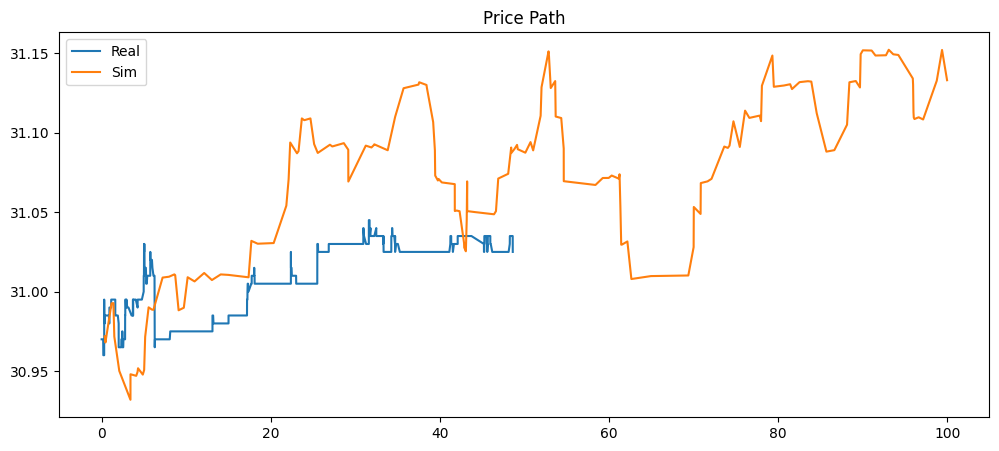

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(real_time[:2000], real_mid[:2000], label="Real")
plt.plot(sim_time[:2000], sim_mid[:2000], label="Sim")
plt.legend(); plt.title("Price Path"); plt.show()

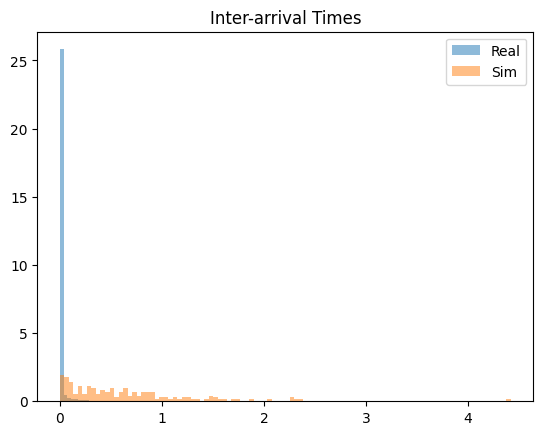

In [ ]:
real_times = np.sort(np.concatenate(timestamps))
sim_times  = np.sort(np.concatenate(sim_events))

plt.hist(np.diff(real_times), bins=100, alpha=0.5, label="Real", density=True)
plt.hist(np.diff(sim_times), bins=100, alpha=0.5, label="Sim", density=True)
plt.legend(); plt.title("Inter-arrival Times"); plt.show()

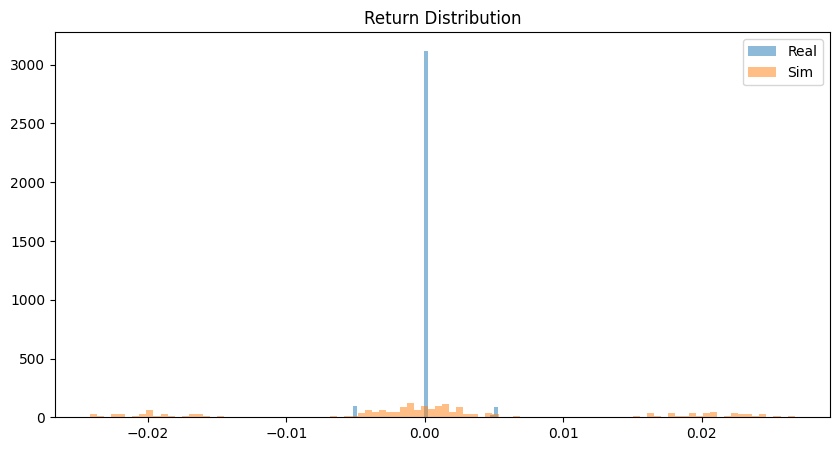

Real volatility: 0.001367836527324547
Sim volatility : 0.01253263573500966


In [ ]:
real_ret = np.diff(real_mid_plot)
sim_ret  = np.diff(sim_mid_plot)

plt.figure(figsize=(10,5))
plt.hist(real_ret, bins=100, alpha=0.5, label="Real", density=True)
plt.hist(sim_ret, bins=100, alpha=0.5, label="Sim", density=True)

plt.legend()
plt.title("Return Distribution")
plt.show()

print("Real volatility:", np.std(real_ret))
print("Sim volatility :", np.std(sim_ret))

In [ ]:
print("Real range:", real_mid_plot.min(), real_mid_plot.max())
print("Sim range :", sim_mid_plot.min(), sim_mid_plot.max())

Real range: 30.96 31.075
Sim range : 30.931956362909762 31.152204724689064


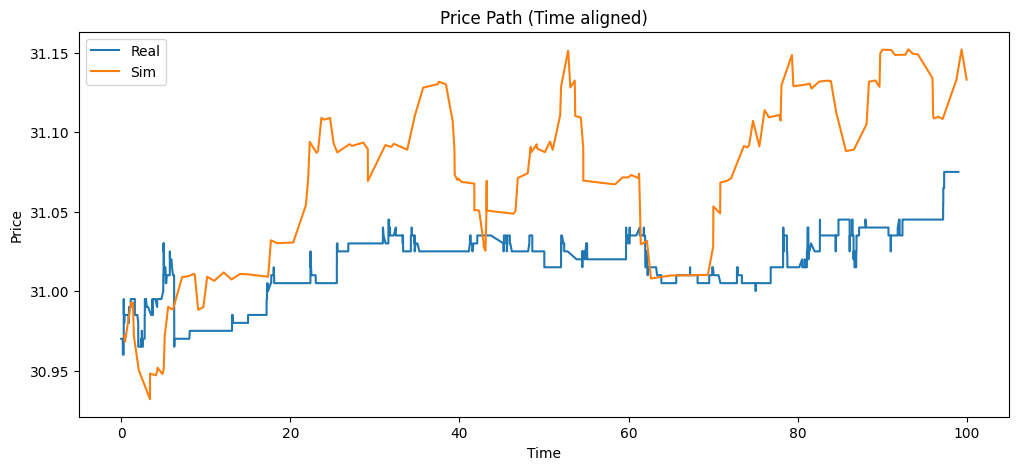

In [ ]:
T_plot = min(real_time[-1], sim_time[-1])

real_mask = real_time <= T_plot
sim_mask  = sim_time <= T_plot

plt.figure(figsize=(12,5))

plt.plot(real_time[real_mask], real_mid[real_mask], label="Real")
plt.plot(sim_time[sim_mask], sim_mid[sim_mask], label="Sim")

plt.legend()
plt.title("Price Path (Time aligned)")
plt.xlabel("Time")
plt.ylabel("Price")
plt.show()